# LAB 04 - Text Classification: Experiments

Bài toán: sentiment classification (Option A) trên IMDb, positive / negative.
Preprocessing nằm trong `preprocessing.py`. Notebook ghi `results.csv` và `confusion_matrix.png`.

## 0. Setup

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.frozen import FrozenEstimator
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

from preprocessing import (LABEL_NAMES, MeanEmbeddingVectorizer, class_distribution, clean_text,
                           deduplicate, inspect_dataset, load_imdb, preprocess, remove_overlap,
                           split_train_val, tokenize)

SEED = 42
C_GRID = [0.25, 1, 4, 16]          # chọn C trên validation
pd.set_option("display.max_colwidth", 200)

RESULTS = []
def log(experiment, model, setting, split, metric, value):
    RESULTS.append({"experiment": experiment, "model": model, "setting": setting,
                    "split": split, "metric": metric, "value": value})

def metrics(y_true, y_pred):
    # positive (label 1) là positive class
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0)}

def tfidf(**kw):
    # clean_text + tokenize của preprocessing.py, min_df = 2, sublinear tf
    params = dict(preprocessor=clean_text, tokenizer=tokenize, token_pattern=None,
                  lowercase=False, min_df=2, sublinear_tf=True)
    params.update(kw)
    return TfidfVectorizer(**params)

## 1. Experiment 1 - Dataset inspection

IMDb (Hugging Face `stanfordnlp/imdb`): 25,000 review train và 25,000 review test, label 0 = negative, 1 = positive.

In [2]:
train_raw, test_raw = load_imdb()
inspection = pd.DataFrame([inspect_dataset(train_raw, "train"), inspect_dataset(test_raw, "test")]).set_index("split")
for split, row in inspection.iterrows():
    for k, v in row.items():
        log("exp1_inspection", "-", "raw", split, k, v)
inspection.round(1)

,samples,classes,missing_text,missing_label,duplicate_docs,len_mean,len_median,len_min,len_max
split,,,,,,,,,
train,25000,2,0,0,96,233.6,174.0,10,2473
test,25000,2,0,0,199,228.3,172.0,6,2246


In [3]:
pd.concat({"train": class_distribution(train_raw), "test": class_distribution(test_raw)}, axis=1).round(2)

train              test           
          Count Percentage  Count Percentage
Class                                       
negative  12500       50.0  12500       50.0
positive  12500       50.0  12500       50.0

In [4]:
overlap = set(train_raw["text"]) & set(test_raw["text"])
print("Document trùng giữa train và test:", len(overlap))
dup_groups = train_raw[train_raw["text"].duplicated(keep=False)]
conflict = dup_groups.groupby("text")["label"].nunique().gt(1).sum()
print("Nhóm duplicate trong train có label mâu thuẫn:", conflict)
print("Ví dụ review gốc:", train_raw["text"].iloc[1][:400])
log("exp1_inspection", "-", "raw", "train&test", "overlap_docs", len(overlap))

Document trùng giữa train và test: 123
Nhóm duplicate trong train có label mâu thuẫn: 0
Ví dụ review gốc: "I Am Curious: Yellow" is a risible and pretentious steaming pile. It doesn't matter what one's political views are because this film can hardly be taken seriously on any level. As for the claim that frontal male nudity is an automatic NC-17, that isn't true. I've seen R-rated films with male nudity. Granted, they only offer some fleeting views, but where are the R-rated films with gaping vulvas a


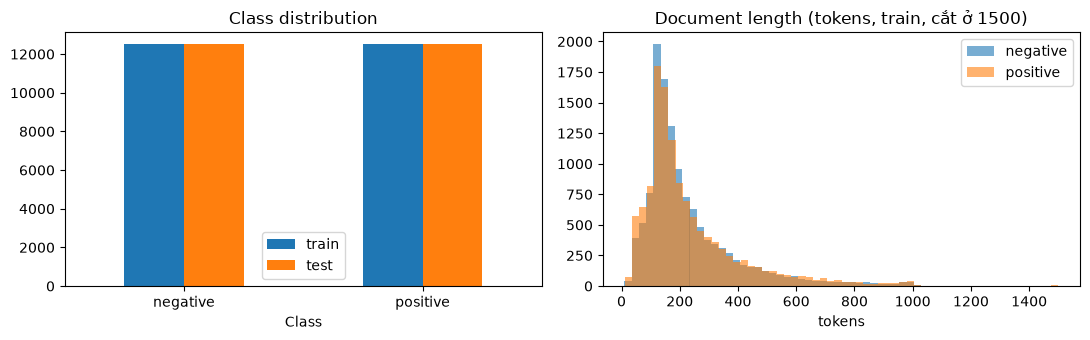

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
dist = pd.concat({"train": class_distribution(train_raw)["Count"],
                  "test": class_distribution(test_raw)["Count"]}, axis=1)
dist.plot.bar(ax=axes[0], rot=0, title="Class distribution")
lengths = train_raw["text"].map(lambda t: len(preprocess(t)))
for lab, name in LABEL_NAMES.items():
    axes[1].hist(lengths[train_raw["label"] == lab].clip(upper=1500), bins=60, alpha=0.6, label=name)
axes[1].set(title="Document length (tokens, train, cắt ở 1500)", xlabel="tokens")
axes[1].legend()
plt.tight_layout()
plt.show()

Dataset cân bằng (50/50 ở cả train và test), không có missing text/label. Có duplicate trong từng tập và trùng giữa train với test, cần xử lý trước khi split.

Làm sạch và chia dữ liệu:
- bỏ duplicate trong train và trong test;
- bỏ các review test đã xuất hiện trong train;
- chia train thành train/validation 80/20 (stratified, seed 42). Validation dùng để chọn C, test chỉ dùng để báo cáo cuối.

In [6]:
train_full = deduplicate(train_raw)
test_df = remove_overlap(deduplicate(test_raw), train_full)
train_df, val_df = split_train_val(train_full, val_size=0.2, seed=SEED)

X_train, y_train = train_df["text"].tolist(), train_df["label"].values
X_val, y_val = val_df["text"].tolist(), val_df["label"].values
X_test, y_test = test_df["text"].tolist(), test_df["label"].values

split_stats = pd.DataFrame({name: {"samples": len(d), "positive %": 100 * d["label"].mean()}
                            for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]}).T
for split, row in split_stats.iterrows():
    log("exp1_split", "-", "dedup", split, "samples", row["samples"])
    log("exp1_split", "-", "dedup", split, "positive_pct", row["positive %"])
split_stats.round(2)

,samples,positive %
train,19923.0,50.08
validation,4981.0,50.09
test,24678.0,50.30


## 2. Data leakage

Đúng: split → fit TF-IDF trên TRAIN → transform validation/test.
Sai: fit TF-IDF trên toàn bộ dữ liệu (train + test) rồi mới split.

In [7]:
vec_ok = tfidf().fit(X_train)
vec_leak = tfidf().fit(X_train + X_test)
vocab_ok, vocab_leak = set(vec_ok.vocabulary_), set(vec_leak.vocabulary_)
test_only = sorted(vocab_leak - vocab_ok)
print("Vocabulary fit trên train:", len(vocab_ok))
print("Vocabulary fit trên train + test:", len(vocab_leak))
print("Số term chỉ có nhờ test:", len(test_only), "ví dụ:", test_only[:10])

w = "movie"
print(f"IDF({w}): train-only = {vec_ok.idf_[vec_ok.vocabulary_[w]]:.4f}, "
      f"train+test = {vec_leak.idf_[vec_leak.vocabulary_[w]]:.4f}")

rows = []
for name, vec in [("fit on train (đúng)", vec_ok), ("fit on train+test (leakage)", vec_leak)]:
    clf = LogisticRegression(C=4, max_iter=2000).fit(vec.transform(X_train), y_train)
    m = metrics(y_test, clf.predict(vec.transform(X_test)))
    rows.append({"setting": name, "vocabulary": len(vec.vocabulary_), **m})
    for k, v in m.items():
        log("leakage", "TF-IDF + LR", name, "test", k, v)
pd.DataFrame(rows).set_index("setting").round(4)

Vocabulary fit trên train: 43172
Vocabulary fit trên train + test: 61112
Số term chỉ có nhờ test: 17940 ví dụ: ["0's", "007's", '0079', '08th', '0f', "1's", "100's", "1000's", '10000', '1000000']
IDF(movie): train-only = 1.4969, train+test = 1.4968


,vocabulary,accuracy,precision,recall,f1
setting,,,,,
fit on train (đúng),43172,0.8899,0.8915,0.8894,0.8904
fit on train+test (leakage),61112,0.8897,0.8921,0.8882,0.8901


Với IMDb, chênh lệch nhỏ vì train đã đủ lớn, nhưng vocabulary và IDF đã chứa thông tin của test. Kết quả trên test vì vậy không còn là ước lượng trung thực cho dữ liệu chưa thấy.

## 3. Core implementation + Experiment 2 - Baseline TF-IDF + Logistic Regression

Pipeline: raw text → TF-IDF (unigram, min_df = 2, sublinear tf) → Logistic Regression → prediction → evaluation. C được chọn theo F1 trên validation.

In [8]:
def run_model(name, make_pipe, experiment, setting="", grid=C_GRID):
    """Chọn C theo validation F1, ghi train time, metrics trên validation và test."""
    best = None
    for C in grid:
        pipe = make_pipe(C)
        t0 = time.perf_counter()
        pipe.fit(X_train, y_train)
        fit_time = time.perf_counter() - t0
        f1_val = f1_score(y_val, pipe.predict(X_val))
        log(experiment, name, f"{setting} C={C}".strip(), "validation", "f1", f1_val)
        if best is None or f1_val > best[1]:
            best = (C, f1_val, pipe, fit_time)
    C, _, pipe, fit_time = best
    row = {"model": name, "setting": setting, "C": C, "train_time_s": fit_time}
    feat = pipe.steps[0][1]
    if hasattr(feat, "vocabulary_"):
        row["vocabulary"] = len(feat.vocabulary_)
    for split, X, y in [("validation", X_val, y_val), ("test", X_test, y_test)]:
        for k, v in metrics(y, pipe.predict(X)).items():
            row[f"{split}_{k}"] = v
    for k, v in row.items():
        if k not in ("model", "setting"):
            split = "test" if k.startswith("test_") else "validation" if k.startswith("validation_") else "-"
            log(experiment, name, setting or "best", split, k.replace("test_", "").replace("validation_", ""), v)
    return pipe, row

lr_tfidf = lambda C: Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(C=C, max_iter=2000))])
model_A, row_A = run_model("TF-IDF + LR", lr_tfidf, "exp2_baseline", "unigram")
pd.DataFrame([row_A]).set_index("model").round(4).T

model,TF-IDF + LR
setting,unigram
C,4
train_time_s,3.8634
vocabulary,43172
validation_accuracy,0.8948
validation_precision,0.8866
validation_recall,0.9058
validation_f1,0.8961
test_accuracy,0.8899
test_precision,0.8915


Kiểm tra lại z = wᵀx + b và P(y = 1|x) = σ(z) với một review test.

In [9]:
vec_A, clf_A = model_A.named_steps["tfidf"], model_A.named_steps["clf"]
x = vec_A.transform([X_test[0]])
z = (x @ clf_A.coef_.ravel())[0] + clf_A.intercept_[0]
print(f"z tự tính = {z:.6f}, decision_function = {model_A.decision_function([X_test[0]])[0]:.6f}")
print(f"sigma(z) = {1 / (1 + np.exp(-z)):.6f}, predict_proba = {model_A.predict_proba([X_test[0]])[0, 1]:.6f}")

z tự tính = -3.663759, decision_function = -3.663759
sigma(z) = 0.024995, predict_proba = 0.024995


## 4. Experiment 3 - Representation comparison

- Model A: TF-IDF + Logistic Regression (mục 3).
- Model B: Average Word2Vec + Logistic Regression. Word2Vec Skip-gram (d = 100, window = 5, min_count = 5, epochs = 10) được train trong `fit()`, tức chỉ trên TRAIN. Vector document được chuẩn hoá bằng StandardScaler trước LR.
- Model C: TF-IDF + Linear SVM.

In [10]:
# Word2Vec chỉ phụ thuộc train nên train 1 lần rồi dùng lại cho mọi C
t0 = time.perf_counter()
mev = MeanEmbeddingVectorizer(vector_size=100, window=5, min_count=5, sg=1, epochs=10, workers=4, seed=SEED).fit(X_train)
w2v_time = time.perf_counter() - t0
print(f"Word2Vec train time: {w2v_time:.1f} s, vocabulary: {len(mev.w2v_.wv)}")
log("exp3_representation", "Avg Word2Vec + LR", "word2vec", "-", "w2v_train_time_s", w2v_time)
log("exp3_representation", "Avg Word2Vec + LR", "word2vec", "-", "w2v_vocabulary", len(mev.w2v_.wv))

# FrozenEstimator: dùng lại Word2Vec đã fit, Pipeline không fit lại
lr_w2v = lambda C: Pipeline([("w2v", FrozenEstimator(mev)), ("scale", StandardScaler()),
                             ("clf", LogisticRegression(C=C, max_iter=2000))])
model_B, row_B = run_model("Avg Word2Vec + LR", lr_w2v, "exp3_representation")
row_B["train_time_s"] += w2v_time      # tính cả thời gian train Word2Vec
log("exp3_representation", "Avg Word2Vec + LR", "best", "-", "train_time_incl_w2v_s", row_B["train_time_s"])

svm_tfidf = lambda C: Pipeline([("tfidf", tfidf()), ("clf", LinearSVC(C=C))])
model_C, row_C = run_model("TF-IDF + Linear SVM", svm_tfidf, "exp3_representation", grid=[0.05, 0.25, 1, 4])
row_A3 = dict(row_A)
for k, v in row_A3.items():
    if k not in ("model", "setting"):
        split = "test" if k.startswith("test_") else "validation" if k.startswith("validation_") else "-"
        log("exp3_representation", "TF-IDF + LR", "best", split, k.replace("test_", "").replace("validation_", ""), v)

comparison = pd.DataFrame([row_A3, row_B, row_C]).set_index("model")
cols = ["C", "train_time_s", "validation_f1", "test_accuracy", "test_precision", "test_recall", "test_f1"]
comparison[cols].round(4)

Word2Vec train time: 79.6 s, vocabulary: 27006


,C,train_time_s,validation_f1,test_accuracy,test_precision,test_recall,test_f1
model,,,,,,,
TF-IDF + LR,4.00,3.8634,0.8961,0.8899,0.8915,0.8894,0.8904
Avg Word2Vec + LR,1.00,88.5786,0.8687,0.8597,0.8684,0.8498,0.8590
TF-IDF + Linear SVM,0.25,3.7464,0.8975,0.8900,0.8909,0.8904,0.8906


Láng giềng gần nhất trong Word2Vec train trên IMDb.

In [11]:
for w in ["good", "bad", "boring", "excellent", "not"]:
    print(w, "→", [(x, round(s, 2)) for x, s in mev.w2v_.wv.most_similar(w, topn=6)])
print("cos(good, bad) =", round(float(mev.w2v_.wv.similarity("good", "bad")), 3))

good → [('decent', 0.79), ('great', 0.78), ('nice', 0.73), ('bad', 0.71), ('fine', 0.69), ('ok', 0.64)]
bad → [('terrible', 0.77), ('horrible', 0.75), ('awful', 0.73), ('good', 0.71), ('lousy', 0.7), ('cheezy', 0.69)]
boring → [('dull', 0.86), ('tedious', 0.8), ('dreadfully', 0.79), ('pointless', 0.77), ('uninteresting', 0.77), ('uninspiring', 0.76)]
excellent → [('outstanding', 0.83), ('exceptional', 0.74), ('fantastic', 0.74), ('superb', 0.73), ('terrific', 0.72), ('amazing', 0.72)]
not → [("isn't", 0.72), ('nitpicking', 0.67), ('wasnt', 0.66), ("wasn't", 0.66), ('legitimately', 0.66), ('citing', 0.64)]
cos(good, bad) = 0.709


TF-IDF + LR và TF-IDF + SVM gần như bằng nhau (F1 0.890 và 0.891), Avg Word2Vec thấp hơn khoảng 3 điểm và chậm hơn nhiều. Láng giềng của good có cả bad (cos = 0.709): embedding học co-occurrence, không học cực tính cảm xúc.

## 5. Experiment 4 - Word order

S1 = "this movie is good", S2 = "this movie is not good". Với average embedding, v = 1/n Σ vᵢ, nên not chỉ được cộng thêm vào trung bình.

In [12]:
def cos(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

pairs = [("this movie is good", "this movie is not good"),
         ("this movie is good", "good is movie this"),
         ("i like this movie", "i do not like this movie"),
         ("not bad at all", "bad")]
rows = []
for s1, s2 in pairs:
    v1, v2 = mev.transform([s1, s2])
    t1, t2 = vec_A.transform([s1, s2])
    rows.append({"S1": s1, "S2": s2, "cos AvgW2V": cos(v1, v2),
                 "cos TF-IDF": float((t1 @ t2.T).toarray()[0, 0]),
                 "P(pos|S1) A": model_A.predict_proba([s1])[0, 1], "P(pos|S2) A": model_A.predict_proba([s2])[0, 1],
                 "P(pos|S1) B": model_B.predict_proba([s1])[0, 1], "P(pos|S2) B": model_B.predict_proba([s2])[0, 1]})
    log("exp4_word_order", "Avg Word2Vec", f"{s1} | {s2}", "-", "cosine", rows[-1]["cos AvgW2V"])
    for m in ("A", "B"):
        log("exp4_word_order", m, s1, "-", "p_pos", rows[-1][f"P(pos|S1) {m}"])
        log("exp4_word_order", m, s2, "-", "p_pos", rows[-1][f"P(pos|S2) {m}"])
word_order = pd.DataFrame(rows)
word_order.round(3)

,S1,S2,cos AvgW2V,cos TF-IDF,P(pos|S1) A,P(pos|S2) A,P(pos|S1) B,P(pos|S2) B
0,this movie is good,this movie is not good,0.976,0.887,0.825,0.370,0.994,0.714
1,this movie is good,good is movie this,1.000,1.000,0.825,0.825,0.994,0.994
2,i like this movie,i do not like this movie,0.951,0.717,0.300,0.049,0.515,0.029
3,not bad at all,bad,0.741,0.659,0.000,0.000,0.000,0.000


In [13]:
# Đóng góp w_j * x_j của từng term trong S2 (Model A)
coef_A = clf_A.coef_.ravel()
x2 = vec_A.transform(["this movie is not good"])
contrib = {vec_A.get_feature_names_out()[j]: coef_A[j] * x2[0, j] for j in x2.nonzero()[1]}
pd.Series(contrib).sort_values().round(3)

not     -1.865
this    -0.448
movie   -0.390
is       0.493
good     2.063
dtype: float64

Average embedding gần như không đổi khi thêm not (cos = 0.976), Model B vẫn đoán S2 là positive. Model A đoán đúng S2 chỉ vì not có weight âm chung chung, good vẫn đóng góp dương. "not bad at all" bị mọi model đoán negative.

## 6. Experiment 5 - n-gram features

TF-IDF unigram so với unigram + bigram, cùng Logistic Regression, cùng cách chọn C.

In [14]:
lr_bi = lambda C: Pipeline([("tfidf", tfidf(ngram_range=(1, 2))), ("clf", LogisticRegression(C=C, max_iter=2000))])
model_A2, row_A2 = run_model("TF-IDF + LR", lr_bi, "exp5_ngram", "uni+bigram")
ngram = pd.DataFrame([{**row_A, "setting": "unigram"}, row_A2]).set_index("setting")
ngram[["vocabulary", "C", "train_time_s", "validation_f1", "test_f1", "test_accuracy"]].round(4)

,vocabulary,C,train_time_s,validation_f1,test_f1,test_accuracy
setting,,,,,,
unigram,43172,4,3.8634,0.8961,0.8904,0.8899
uni+bigram,365203,16,16.0711,0.9067,0.9074,0.9066


In [15]:
vec_A2, clf_A2 = model_A2.named_steps["tfidf"], model_A2.named_steps["clf"]
coef_A2 = pd.Series(clf_A2.coef_.ravel(), index=vec_A2.get_feature_names_out())
print(coef_A2[["good", "not", "not good", "very good", "not bad", "bad"]].round(3))
for s in ["this movie is good", "this movie is not good", "not bad at all"]:
    p = model_A2.predict_proba([s])[0, 1]
    print(f"P(pos | '{s}') uni+bigram = {p:.3f}")
    log("exp5_ngram", "TF-IDF + LR uni+bigram", s, "-", "p_pos", p)

good          4.002
not          -5.280
not good     -2.372
very good     4.566
not bad       1.594
bad         -15.827
dtype: float64
P(pos | 'this movie is good') uni+bigram = 0.932
P(pos | 'this movie is not good') uni+bigram = 0.055
P(pos | 'not bad at all') uni+bigram = 0.006


Bigram tăng F1 từ 0.890 lên 0.907, "not good" và "very good" thành feature riêng, nhưng vocabulary tăng 8.5 lần và train lâu hơn khoảng 4 lần.

## 7. Vocabulary size và stopwords (kiểm tra Prediction 3, 4)

Cùng TF-IDF unigram + LR, C cố định bằng C tốt nhất của baseline.

In [16]:
C_best = row_A["C"]
def quick(vec):
    pipe = Pipeline([("tfidf", vec), ("clf", LogisticRegression(C=C_best, max_iter=2000))])
    t0 = time.perf_counter(); pipe.fit(X_train, y_train); t = time.perf_counter() - t0
    m_val = metrics(y_val, pipe.predict(X_val)); m_test = metrics(y_test, pipe.predict(X_test))
    return {"vocabulary": len(pipe.steps[0][1].vocabulary_), "train_time_s": t,
            "val_accuracy": m_val["accuracy"], "val_f1": m_val["f1"],
            "test_accuracy": m_test["accuracy"], "test_f1": m_test["f1"]}

rows = []
for mf in [100, 500, 1000, 5000, 20000, None]:
    r = {"setting": f"max_features={mf}", **quick(tfidf(max_features=mf))}
    rows.append(r)
stop = sorted(ENGLISH_STOP_WORDS)
negations = {"not", "no", "nor", "never", "nothing", "cannot"}
rows.append({"setting": "bỏ stopwords (sklearn)", **quick(tfidf(stop_words=stop))})
rows.append({"setting": "bỏ stopwords, giữ phủ định", **quick(tfidf(stop_words=[w for w in stop if w not in negations]))})
vocab_stop = pd.DataFrame(rows).set_index("setting")
for s, r in vocab_stop.iterrows():
    for k, v in r.items():
        log("exp_vocab_stopwords", "TF-IDF + LR", s, "test" if k.startswith("test") else "validation" if k.startswith("val") else "-", k, v)
vocab_stop.round(4)

,vocabulary,train_time_s,val_accuracy,val_f1,test_accuracy,test_f1
setting,,,,,,
max_features=100,100,4.1553,0.7167,0.7188,0.7287,0.7317
max_features=500,500,3.9567,0.8326,0.8343,0.8428,0.8448
max_features=1000,1000,3.9996,0.8645,0.8662,0.8664,0.8681
max_features=5000,5000,3.9934,0.8844,0.8858,0.8839,0.8847
max_features=20000,20000,4.2238,0.8942,0.8956,0.8873,0.8877
max_features=None,43172,5.5489,0.8948,0.8961,0.8899,0.8904
bỏ stopwords (sklearn),42862,3.1881,0.8918,0.8935,0.8829,0.8835
"bỏ stopwords, giữ phủ định",42868,2.8662,0.8926,0.8939,0.8842,0.8847


Tăng vocabulary làm F1 tăng nhưng bão hoà từ khoảng 20,000 từ. Bỏ stopwords làm F1 giảm vì danh sách của sklearn có not, no, never, very, but, well.

## 8. Evaluation

Positive class = positive (label 1). Bảng cuối trên test.

In [17]:
final_models = {"TF-IDF + LR": model_A, "Avg Word2Vec + LR": model_B,
                "TF-IDF + Linear SVM": model_C, "TF-IDF (uni+bigram) + LR": model_A2}
preds = {name: m.predict(X_test) for name, m in final_models.items()}
final = pd.DataFrame({name: metrics(y_test, p) for name, p in preds.items()}).T
for name, r in final.iterrows():
    for k, v in r.items():
        log("evaluation", name, "final", "test", k, v)
final.round(4)

,accuracy,precision,recall,f1
TF-IDF + LR,0.8899,0.8915,0.8894,0.8904
Avg Word2Vec + LR,0.8597,0.8684,0.8498,0.8590
TF-IDF + Linear SVM,0.8900,0.8909,0.8904,0.8906
TF-IDF (uni+bigram) + LR,0.9066,0.9047,0.9102,0.9074


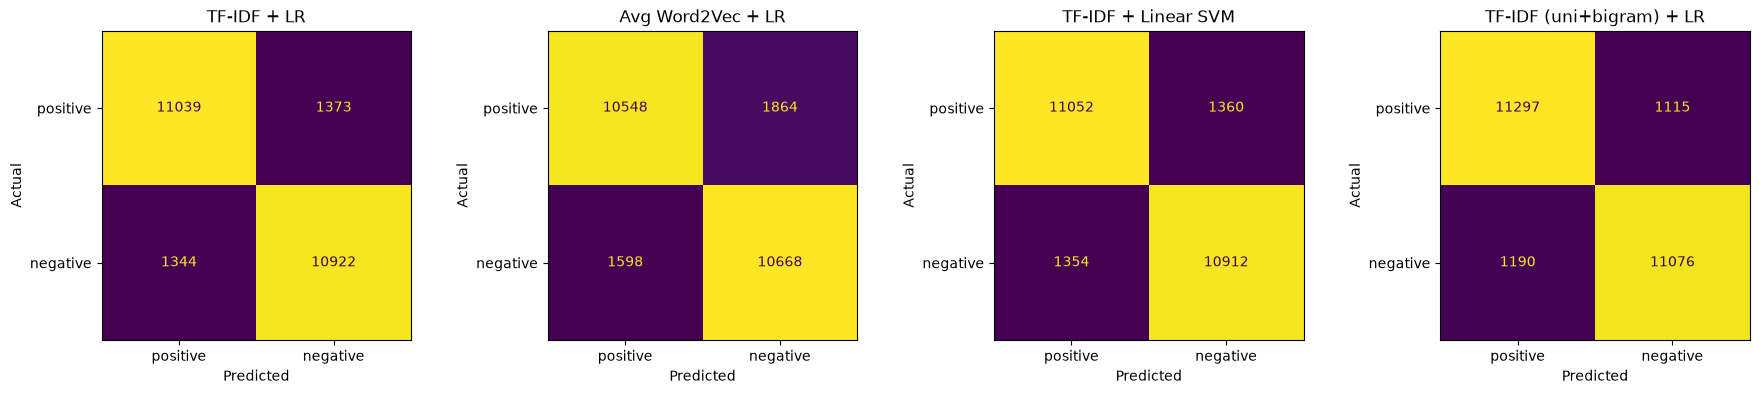

,TP,FN,FP,TN
model,,,,
TF-IDF + LR,11039,1373,1344,10922
Avg Word2Vec + LR,10548,1864,1598,10668
TF-IDF + Linear SVM,11052,1360,1354,10912
TF-IDF (uni+bigram) + LR,11297,1115,1190,11076


In [18]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
cm_rows = []
for ax, (name, p) in zip(axes, preds.items()):
    # hàng = actual, cột = predicted, thứ tự [positive, negative] giống đề
    cm = confusion_matrix(y_test, p, labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=["positive", "negative"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set(title=name, xlabel="Predicted", ylabel="Actual")
    tp, fn, fp, tn = cm.ravel()
    cm_rows.append({"model": name, "TP": tp, "FN": fn, "FP": fp, "TN": tn})
    for k, v in cm_rows[-1].items():
        if k != "model":
            log("evaluation", name, "confusion_matrix", "test", k, v)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame(cm_rows).set_index("model")

Model A: FN 1,373 và FP 1,344, hai class bị nhầm gần như bằng nhau. Avg Word2Vec có FN nhiều hơn nên recall (0.850) thấp hơn precision (0.868).

Accuracy và F1 trên một tập test mất cân bằng: lấy toàn bộ negative và 5% positive của test (giống Bài 4).

In [19]:
rng = np.random.default_rng(SEED)
pos_idx, neg_idx = np.where(y_test == 1)[0], np.where(y_test == 0)[0]
n_pos = int(round(len(neg_idx) * 5 / 95))
idx = np.concatenate([neg_idx, rng.choice(pos_idx, n_pos, replace=False)])
Xi, yi = [X_test[i] for i in idx], y_test[idx]
dummy = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(yi), 1)), yi)
imb = pd.DataFrame({"Majority (luôn negative)": metrics(yi, dummy.predict(np.zeros((len(yi), 1)))),
                    "TF-IDF + LR": metrics(yi, model_A.predict(Xi))}).T
print(f"negative = {len(neg_idx)}, positive = {n_pos}")
for name, r in imb.iterrows():
    for k, v in r.items():
        log("evaluation_imbalanced", name, "95/5", "test", k, v)
imb.round(4)

negative = 12266, positive = 646


,accuracy,precision,recall,f1
Majority (luôn negative),0.950,0.0000,0.0000,0.0000
TF-IDF + LR,0.891,0.3022,0.9009,0.4526


Model luôn đoán negative có accuracy cao hơn TF-IDF + LR (0.950 so với 0.891) nhưng recall và F1 bằng 0.

## 9. Error analysis

Dùng Model A (TF-IDF unigram + LR). Ưu tiên review ngắn để dễ đọc.

In [20]:
proba_A = model_A.predict_proba(X_test)[:, 1]
ea = test_df.assign(pred=preds["TF-IDF + LR"], p_pos=proba_A,
                    n_tokens=[len(preprocess(t)) for t in X_test],
                    text_clean=[" ".join(preprocess(t)) for t in X_test])
ea["correct"] = ea["pred"] == ea["label"]
ea["has_negation"] = ea["text_clean"].str.contains(r"\b(?:not|no|never|n't|isn't|wasn't|don't|doesn't)\b")
summary = ea.groupby("correct").agg(n=("label", "size"), median_tokens=("n_tokens", "median"),
                                    negation_rate=("has_negation", "mean"),
                                    mean_confidence=("p_pos", lambda p: np.mean(np.abs(p - 0.5) + 0.5)))
summary

,n,median_tokens,negation_rate,mean_confidence
correct,,,,
False,2717,177.0,0.838425,0.679431
True,21961,172.0,0.827012,0.868210


In [21]:
short = ea[ea["n_tokens"].between(20, 90)]
print("Đúng, tự tin cao:")
correct = short[short["correct"]].assign(conf=lambda d: (d["p_pos"] - 0.5).abs()).sort_values("conf", ascending=False)
display(pd.concat([correct[correct.label == 1].head(3), correct[correct.label == 0].head(3)])[["text", "label", "pred", "p_pos"]])

Đúng, tự tin cao:


,text,label,pred,p_pos
24091,"ANOTHER great performance by Kiefer Sutherland. I love his movies, because he always plays his role very well. For a low budget film, this was done very good, and kept me on the edge the whole tim...",1,1,0.999704
19894,Excellent story of lives that need repair....one of those rare films that I could watch with my 7 and 8 year old daughters... Glenn Close was excellent in the title role. It was also nice to see C...,1,1,0.999608
19905,"What a great movie!! It's a touching story about four high-school friends who grow up in the 1960s. Throughout the decade, the friends are somewhat separated, but they mnnage to see each other occ...",1,1,0.999374
3941,This was a very disappointing movie. I would definitely call this the worst movie of all time.<br /><br />The acting and writing were poor. And the jokes were not funny.<br /><br />I don't see why...,0,0,0.000012
1340,"This movie was a complete waste of time. The soundtrack was bad, story was lame and predictable, and the acting was terrible. One of the worst 25 movies I have ever seen. After the first ten minut...",0,0,0.000017
11961,"One of the worst movies I've ever seen!!! Absolutely awful. Poor acting, poor story, there isn't one redeeming quality about this movie to recommend. Amistad is much better. Avoid this movie like ...",0,0,0.000028


In [22]:
wrong = short[~short["correct"]].assign(conf=lambda d: (d["p_pos"] - 0.5).abs()).sort_values("conf", ascending=False)
print("False positive (actual negative, predicted positive):")
display(wrong[wrong.label == 0].head(6)[["text", "label", "pred", "p_pos"]])
print("False negative (actual positive, predicted negative):")
display(wrong[wrong.label == 1].head(6)[["text", "label", "pred", "p_pos"]])

False positive (actual negative, predicted positive):


,text,label,pred,p_pos
11859,"This movie was pure genius. John Waters is brilliant. It is hilarious and I am not sick of it even after seeing it about 20 times since I bought it a few months ago. The acting is great, although ...",0,1,0.995785
4020,This is definitely one of the best Kung fu movies in the history of Cinema. The screenplay is really well done (which is not often the case for this type of movies) and you can see that Chuck (in ...,0,1,0.995395
3469,"This film has the language, the style and the attitude down ... plus greats rides from Occy (a world champ) and the great Jerry Lopez. John Philbin as Turtle has the surf pidgin down, and the surf...",0,1,0.990520
2647,"I really liked this quirky movie. The characters are not the bland beautiful people that show up in so many movies and on TV. It has a realistic edge, with a captivating story line. The main title...",0,1,0.981784
128,"There must be an error. This movie belongs with ""Plan 9"", and a lot others as a quite entertaining, silly diversion. You'll never accept you like it, yet you will watch it whenever it comes out on...",0,1,0.979660
298,"This is, without a doubt, the most hilarious movie I've ever seen. Seriously, if the makers of this movie are ever discovered, they'll put guys like Jim Carrey out of a job. Rent ""Jack-O"" tonight!...",0,1,0.977211


False negative (actual positive, predicted negative):


,text,label,pred,p_pos
12735,"David Morse and Andre Braugher are very talented actors, which is why I'm trying so hard to support this program. Unfortunately, an irrational plot, and very poor writing is making it difficult fo...",1,0,0.018029
17840,"If you're looking for a not-so-serious mob movie, with a female as the lead, you're in the right place. Pfieffer has acted much better than this. You can see she has matured beyond this picture.<b...",1,0,0.019112
20687,"This HAS to be my guilty pleasure. I am a HUGE fan of 80's movies that were designed to entertain and they didn't care if they offended anyone. This move has no meat, not substance, no deep though...",1,0,0.031429
16332,"I just wanted to say that. I love Gheorghe Muresan, so I automatically loved this movie. Everything else about it was so-so... Billy Crystal is a good actor, even if he is annoying. But the thing ...",1,0,0.047182
20691,"It's not Citizen Kane, but it does deliver. Cleavage, and lots of it.<br /><br />Badly acted and directed, poorly scripted. Who cares? I didn't watch it for the dialog.",1,0,0.052715
16248,"Contains Spoiler The movie is a good action/comedy but i don't know if the director cut too many parts but it seems that the bad guy die too fast. The end of the movie come, the bad guy dies and t...",1,0,0.053647


In [23]:
# Đóng góp w_j * x_j lớn nhất của các review sai ở trên
names_A = vec_A.get_feature_names_out()
def top_contrib(text, k=6):
    x = vec_A.transform([text])
    c = sorted(((names_A[j], coef_A[j] * x[0, j]) for j in x.nonzero()[1]), key=lambda t: t[1])
    return {"most negative": [(w, round(v, 2)) for w, v in c[:k]],
            "most positive": [(w, round(v, 2)) for w, v in c[::-1][:k]]}

for i, r in pd.concat([wrong[wrong.label == 0].head(6), wrong[wrong.label == 1].head(6)]).iterrows():
    print(i, LABEL_NAMES[r.label], "→", LABEL_NAMES[r.pred], round(r.p_pos, 3), top_contrib(r.text))

11859 negative → positive 0.996 {'most negative': [('even', np.float64(-0.24)), ('am', np.float64(-0.24)), ('rent', np.float64(-0.23)), ('been', np.float64(-0.21)), ('could', np.float64(-0.21)), ('better', np.float64(-0.2))], 'most positive': [('great', np.float64(0.78)), ('favorite', np.float64(0.72)), ('brilliant', np.float64(0.71)), ('today', np.float64(0.68)), ('9', np.float64(0.62)), ('hilarious', np.float64(0.47))]}
4020 negative → positive 0.995 {'most negative': [('chuck', np.float64(-0.32)), ('not', np.float64(-0.27)), ('screenplay', np.float64(-0.26)), ('actor', np.float64(-0.22)), ('this', np.float64(-0.11)), ('of', np.float64(-0.07))], 'most positive': [('great', np.float64(1.05)), ('masterpiece', np.float64(0.81)), ('best', np.float64(0.74)), ('definitely', np.float64(0.69)), ('well', np.float64(0.49)), ('kung', np.float64(0.32))]}
3469 negative → positive 0.991 {'most negative': [('turtle', np.float64(-0.22)), ('down', np.float64(-0.17)), ('scenes', np.float64(-0.12)), ('

In [24]:
# Model B và model uni+bigram dự đoán thế nào trên các review Model A sai
cases = pd.concat([wrong[wrong.label == 0].head(6), wrong[wrong.label == 1].head(6)])
pd.DataFrame({"true": cases["label"].map(LABEL_NAMES),
              "P(pos) A": cases["p_pos"],
              "P(pos) B": model_B.predict_proba(cases["text"].tolist())[:, 1],
              "P(pos) uni+bigram": model_A2.predict_proba(cases["text"].tolist())[:, 1]}).round(3)

,true,P(pos) A,P(pos) B,P(pos) uni+bigram
11859,negative,0.996,0.997,0.996
4020,negative,0.995,0.999,0.998
3469,negative,0.991,0.995,0.997
2647,negative,0.982,0.993,0.928
128,negative,0.980,0.992,0.974
298,negative,0.977,0.556,0.904
12735,positive,0.018,0.316,0.024
17840,positive,0.019,0.091,0.134
20687,positive,0.031,0.092,0.072
16332,positive,0.047,0.086,0.085


## 10. Inspect model weights (Model A)

In [25]:
weights = pd.Series(coef_A, index=names_A).sort_values()
top = pd.DataFrame({"top positive": weights[::-1].head(20).index, "weight +": weights[::-1].head(20).values.round(3),
                    "top negative": weights.head(20).index, "weight -": weights.head(20).values.round(3)})
for f, v in pd.concat([weights[::-1].head(20), weights.head(20)]).items():
    log("weights", "TF-IDF + LR", "unigram", "-", f, v)
top

,top positive,weight +,top negative,weight -
0,great,9.861,worst,-12.292
1,excellent,8.119,bad,-10.146
2,7,7.978,waste,-9.239
3,perfect,7.230,awful,-8.929
4,best,6.324,boring,-7.882
5,wonderful,6.243,poor,-6.951
6,8,5.615,poorly,-6.877
7,amazing,5.571,disappointment,-6.801
8,favorite,5.253,worse,-6.466
9,brilliant,5.134,dull,-6.056


In [26]:
df_A = pd.Series(np.asarray((vec_A.transform(X_train) > 0).sum(axis=0)).ravel(), index=names_A)
print("Document frequency trong train của một số feature:")
print(df_A[["7", "10", "8", "4", "3", "1", "2", "waste", "excellent", "worst", "great"]])
print("Weight:", weights[["7", "10", "8", "4", "3", "1", "2"]].round(3).to_dict())

Document frequency trong train của một số feature:
7             678
10           2686
8             672
4             944
3            1293
1            1440
2            1815
waste        1059
excellent    1392
worst        1802
great        5045
dtype: int64
Weight: {'7': 7.978, '10': 0.838, '8': 5.615, '4': -4.755, '3': -4.208, '1': -4.688, '2': -2.162}


In [27]:
w2 = coef_A2.sort_values()
pd.DataFrame({"top positive (uni+bigram)": w2[::-1].head(15).index, "w+": w2[::-1].head(15).values.round(3),
              "top negative (uni+bigram)": w2.head(15).index, "w-": w2.head(15).values.round(3)})

,top positive (uni+bigram),w+,top negative (uni+bigram),w-
0,great,14.187,bad,-15.827
1,excellent,11.122,worst,-14.764
2,7,9.781,awful,-12.535
3,perfect,9.505,boring,-11.737
4,wonderful,9.081,the worst,-11.733
5,amazing,7.927,waste,-10.379
6,the best,7.892,poor,-10.330
7,best,7.427,worse,-8.810
8,fun,6.999,terrible,-8.647
9,8,6.929,no,-8.635


## 11. Lưu kết quả

In [28]:
pd.DataFrame(RESULTS).to_csv("results.csv", index=False)
print(len(RESULTS), "dòng đã ghi vào results.csv")

257 dòng đã ghi vào results.csv
